In [29]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import math
import numpy as np


from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer

# Data Extraction

In [2]:
from ucimlrepo import fetch_ucirepo  # pip install ucimlrepo
  
# fetch dataset 
bone_marrow_transplant_children = fetch_ucirepo(id=565) 
  
# data (as pandas dataframes) 
X = bone_marrow_transplant_children.data.features 
y = bone_marrow_transplant_children.data.targets 
  

# Exploratory Data Analysis

The data set describes pediatric patients with several hematologic diseases, who were subject to unrelated donor stem cell transplantation.

This dataset was originally used to identify the most important factors regarding the success or failure of the transplantation procedure.

In [3]:
bone_marrow_transplant_children.metadata # Provides basic dataset information

{'uci_id': 565,
 'name': 'Bone marrow transplant: children',
 'repository_url': 'https://archive.ics.uci.edu/dataset/565/bone+marrow+transplant+children',
 'data_url': 'https://archive.ics.uci.edu/static/public/565/data.csv',
 'abstract': 'The data set describes pediatric patients with several hematologic diseases, who were subject to the unmanipulated allogeneic unrelated donor hematopoietic stem cell transplantation.',
 'area': 'Health and Medicine',
 'tasks': ['Classification', 'Regression'],
 'characteristics': ['Multivariate'],
 'num_instances': 187,
 'num_features': 36,
 'feature_types': ['Integer', 'Real'],
 'demographics': ['Gender', 'Age'],
 'target_col': ['survival_status'],
 'index_col': None,
 'has_missing_values': 'yes',
 'missing_values_symbol': 'NaN',
 'year_of_dataset_creation': 2020,
 'last_updated': 'Fri Nov 03 2023',
 'dataset_doi': '10.24432/C5NP6Z',
 'creators': ['Marek Sikora', 'Łukasz Wróbel', 'Adam Gudyś'],
 'intro_paper': {'ID': 293,
  'type': 'NATIVE',
  'titl

We are dealing with 187 training instances and 36 total features. As the number of training instances is small we should be careful in case of overfitting. Moreover, wee have 36 dimensions which is of high complexity specially considering that we are dealing with a low number of instances. Therefore, data reduction techniques will have to be applied.

The dataset contains missing values given by the value "NaN", we will have to take this into account.

The aim was to verify the hypothesis that increased dosage of CD34+ cells / kg extends overall survival time without simultaneous occurrence of undesirable events affecting patients' quality of life

In [4]:
bone_marrow_transplant_children.variables # Provides a description of all the different variables in the dataset

,name,role,type,demographic,description,units,missing_values
0,Recipientgender,Feature,Binary,Gender,"Male - 1, Female - 0",NaN,no
1,Stemcellsource,Feature,Binary,NaN,Source of hematopoietic stem cells (Peripheral...,NaN,no
2,Donorage,Feature,Integer,Age,Age of the donor at the time of hematopoietic ...,NaN,no
3,Donorage35,Feature,Binary,Age,"Donor age <35 - 0, Donor age >=35 - 1",NaN,no
4,IIIV,Feature,Binary,NaN,Development of acute graft versus host disease...,NaN,no
5,Gendermatch,Feature,Binary,Gender,Compatibility of the donor and recipient accor...,NaN,no
6,DonorABO,Feature,Categorical,NaN,ABO blood group of the donor of hematopoietic ...,NaN,no
7,RecipientABO,Feature,Categorical,NaN,ABO blood group of the recipient of hematopoie...,NaN,yes
8,RecipientRh,Feature,Binary,NaN,Presence of the Rh factor on recipient s red b...,NaN,yes
9,ABOmatch,Feature,Binary,NaN,Compatibility of the donor and the recipient o...,NaN,yes


## Feature Correlation

We will inspect the pairwise correlation between all the features, later on, we will also obtain the correlation to the target features

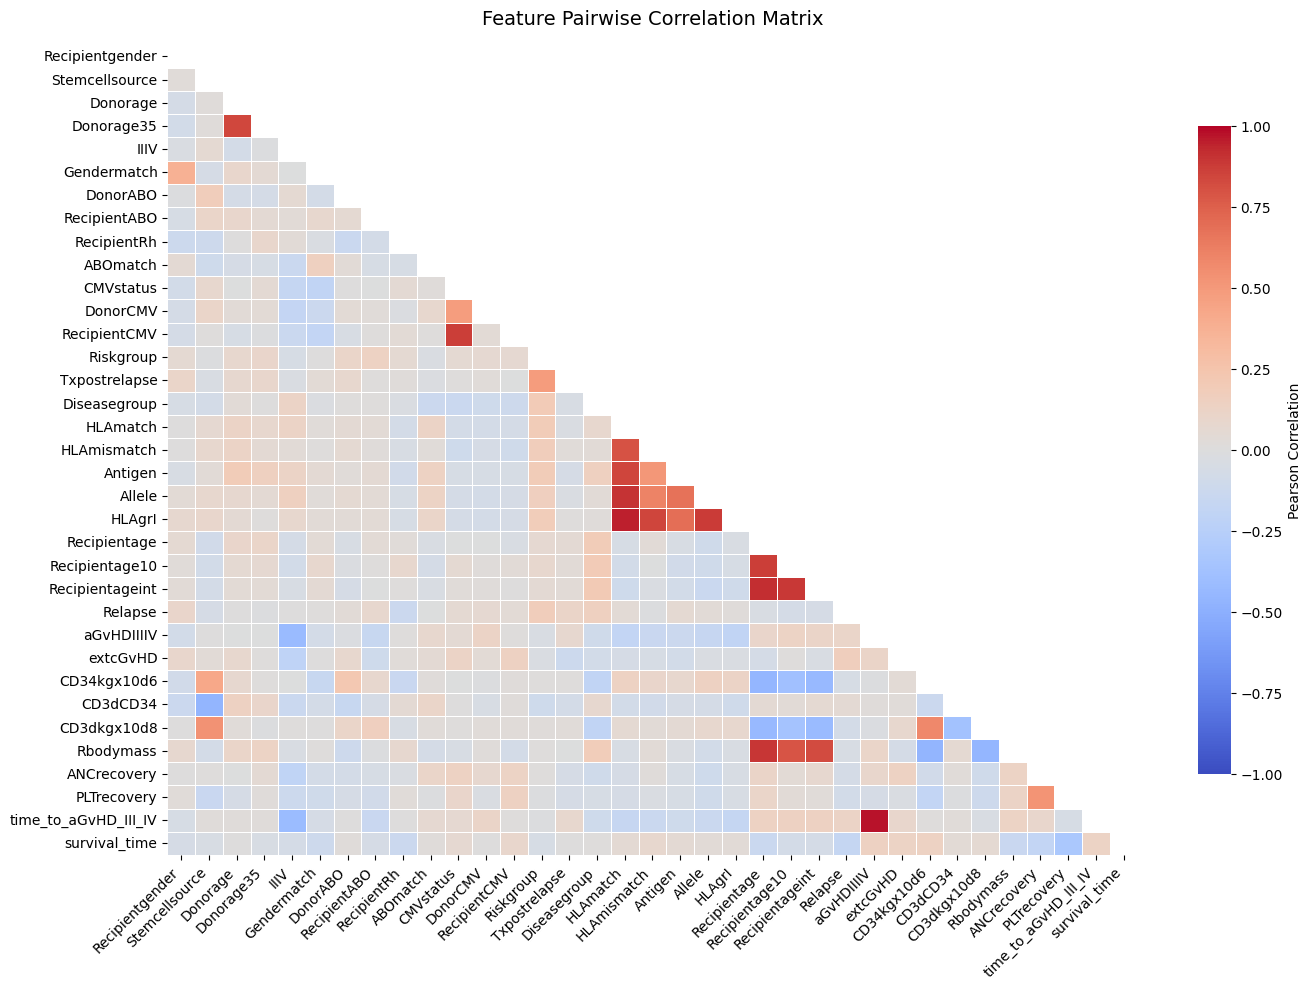

In [5]:
# Correlation to the two target variables
X_corr = bone_marrow_transplant_children.data.features
X_corr_numeric = X_corr.select_dtypes(include=[np.number])

corr_matrix = X_corr_numeric.corr(method="pearson")

plt.figure(figsize=(14, 10))

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    annot=False, 
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation"},
)

plt.title("Feature Pairwise Correlation Matrix", fontsize=14, pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Redundant Variables

As we just saw, there are many features with high correlations

This link explains each of the [variables](https://archive.ics.uci.edu/dataset/565/bone+marrow+transplant+children). For this reason, we will first analyze what each of the variables mean, removing redundant variables, then, we will continue with EDA. For now, this variables will be removed, however, they can be inferred later again as some linear models may benefit from this.

First, we will remove the redundant variables, as they may induce a high collinearity.

- `Donorage`: Feature (Integer): Age of the donor
- `Donorage35`: Binary variable determining if donor age is higher or lower than 35.

As the first one, contains the same information and additional one, we will remove Donorage35.

- `DonorABO`: ABO blood group of the donor
- `RecipientABO`: ABO blood group of the recipient
- `ABOmatch`: Binary variable, if blood cells are compatible 

Third feature can be obtained from the previous two, we will remove it.

- `DonorCMV`: Binary -> Presence of cytomegalovirus infection in the donor of hematopoietic stem cells prior to transplantation (present, absent)
- `RecipientCMV`: Binary -> Presence of cytomegalovirus infection in the donor of hematopoietic stem cells prior to transplantation (present, absent)
- `CMVstatus`: Categorical -> Compatibility of DonorCMV and RecipientC

Same reason as before, redundant information which can be inferred, we will remove CMVstatus

- `Disease`: Feature Categorical. Type of disease, options include nonmalignant, the rest are malignant
- `Diseasegroup`: Either malignant or non-malignant.

Can be inferred from disease, we will remove it

- `HLAMismatch` is a boolean flag which can be derived from other columns. HLAmismatch = 0, whenever HLAmatch = 0, it will be a 1, when the other variable is higher than 0.

We can also remove recipientAge.

- `Recipientage`: Age of the recipient cells at the time of transplantation
- `RecipientAge10`: Binary, whether the age is higher or lower than 10
- `Recipientageint`: Feature Categorical, splits recipient age in bins.

We will remove the last 2 columns here

- `CD3_to_CD34_ration`: CD3+ to CD34+ ration, can be inferred from those 2 columns.

Finally, the variable `survival_time` is treated as a feature. However, as we are dealing with survival analysis, we have to model both the duration until an event occurs or the observation ends (survival time) and the event indicator (whether the event happened or not). For this reason, we will convert to targets

In [6]:
# Removing the redundant columns
cols = ["Donorage35", "ABOmatch", "CMVstatus", "Diseasegroup", "Recipientageint", "Recipientage10",
         "HLAmismatch", "CD3dCD34", "survival_time"] 

feats = bone_marrow_transplant_children.data.features
targets = bone_marrow_transplant_children.data.targets

duration = feats["survival_time"]
event = targets["survival_status"]

y = pd.concat([duration, event], axis=1)

x = feats.drop(columns=cols)

In [7]:
x # Features in our dataset

,Recipientgender,Stemcellsource,Donorage,IIIV,Gendermatch,DonorABO,RecipientABO,RecipientRh,DonorCMV,RecipientCMV,Disease,Riskgroup,Txpostrelapse,HLAmatch,Antigen,Allele,HLAgrI,Recipientage,Relapse,aGvHDIIIIV,extcGvHD,CD34kgx10d6,CD3dkgx10d8,Rbodymass,ANCrecovery,PLTrecovery,time_to_aGvHD_III_IV
0,1,1,22.830137,1,0,1,1.0,1.0,1.0,1.0,ALL,1,0,0,-1.0,-1.0,0,9.6,0,0,1.0,7.20,5.38,35.0,19,51,32
1,1,0,23.342466,1,0,-1,-1.0,1.0,0.0,0.0,ALL,0,0,0,-1.0,-1.0,0,4.0,1,1,1.0,4.50,0.41,20.6,16,37,1000000
2,1,0,26.394521,1,0,-1,-1.0,1.0,0.0,1.0,ALL,0,0,0,-1.0,-1.0,0,6.6,1,1,1.0,7.94,0.42,23.4,23,20,1000000
3,0,0,39.684932,1,0,1,2.0,1.0,1.0,0.0,AML,0,0,0,-1.0,-1.0,0,18.1,0,0,NaN,4.25,0.14,50.0,23,29,19
4,0,1,33.358904,0,0,1,2.0,0.0,0.0,1.0,chronic,1,0,1,1.0,0.0,1,1.3,0,1,1.0,51.85,13.05,9.0,14,14,1000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182,1,1,37.575342,1,0,1,1.0,0.0,1.0,1.0,lymphoma,1,1,0,-1.0,-1.0,0,12.9,1,0,1.0,11.08,4.39,44.0,15,22,16
183,0,1,22.895890,0,0,1,0.0,1.0,0.0,1.0,AML,1,0,0,-1.0,-1.0,0,13.9,0,1,1.0,4.64,4.47,44.5,12,30,1000000
184,0,1,27.347945,1,0,1,-1.0,1.0,1.0,1.0,nonmalignant,0,0,0,-1.0,-1.0,0,10.4,0,1,1.0,7.73,4.73,33.0,16,16,1000000
185,1,1,27.780822,1,0,1,0.0,1.0,0.0,0.0,chronic,0,0,1,1.0,0.0,1,8.0,0,0,0.0,15.41,1.91,24.0,13,14,54


In [8]:
y # Describes survival state, binary, 0 -alive 1-dead. As well as survival time

,survival_time,survival_status
0,999,0
1,163,1
2,435,1
3,53,1
4,2043,0
...,...,...
182,385,1
183,634,1
184,1895,0
185,382,1


We currently have 187 rows with 29 different columns. 27 of them correspond to features, where the remaining ones are the targets

## Variable Leakage

Our main objective is to run a simple analysis on the *Bone Marrow Transplant: children* data, certain variables have information after the transplant is done. However, we want to know, the moment we perform the transplant, the survival status/time of the patient. But there are different variables here which tell us information after the transplant has happened. If we were to deploy our model in the real world, we could not apply it.

For this reason, we researched each of our current variables finding if they were before or after the transplant.

This variables are:

`Relapse`: Relapse of the disease. The recipient had the transplant and later either relapsed or not. Moreover, a relapse its not a death but its an important attribute which provides crucial information

`tx_post_relapse`: The second bone marrow transplantation after relapse. Related to relapse same reason as above

`ANC recovery` and `time_to_ANC_recovery`: Absolute neutrophil count (ANC) measures recoveries of white globules which is usually found in in certain infections. Many of them are lost during transplant, this recovery is seen afterwards. A value of no could mean the patient is dead

`PLT recovery` and `time_to_PLT_recovery`: Platelet recovery. Same reason as for ANC recovery.

Chronic Graft versus Host Disease (CGvHD) appears when the cells from the donor attack or are incompatible with those of the recipient. Therefore, all variables related to it will be removed.

`acute_GvHD_II_III_IV`, `acute_GvHD_III_IV`, `time_to_acute_GvHD_III_IV`, `extensive_chronic_GVHD`, `aGvHDIIIIV`



In [9]:
x.columns

Index(['Recipientgender', 'Stemcellsource', 'Donorage', 'IIIV', 'Gendermatch',
       'DonorABO', 'RecipientABO', 'RecipientRh', 'DonorCMV', 'RecipientCMV',
       'Disease', 'Riskgroup', 'Txpostrelapse', 'HLAmatch', 'Antigen',
       'Allele', 'HLAgrI', 'Recipientage', 'Relapse', 'aGvHDIIIIV', 'extcGvHD',
       'CD34kgx10d6', 'CD3dkgx10d8', 'Rbodymass', 'ANCrecovery', 'PLTrecovery',
       'time_to_aGvHD_III_IV'],
      dtype='str')

In [10]:
leakage_cols = ["Relapse", "Txpostrelapse", "ANCrecovery",  "PLTrecovery", 
                  "IIIV", "time_to_aGvHD_III_IV",
                "aGvHDIIIIV"]

X = x.drop(leakage_cols, axis = 1)

In [11]:
data = pd.concat([X,y], axis = 1)
data

,Recipientgender,Stemcellsource,Donorage,Gendermatch,DonorABO,RecipientABO,RecipientRh,DonorCMV,RecipientCMV,Disease,Riskgroup,HLAmatch,Antigen,Allele,HLAgrI,Recipientage,extcGvHD,CD34kgx10d6,CD3dkgx10d8,Rbodymass,survival_time,survival_status
0,1,1,22.830137,0,1,1.0,1.0,1.0,1.0,ALL,1,0,-1.0,-1.0,0,9.6,1.0,7.20,5.38,35.0,999,0
1,1,0,23.342466,0,-1,-1.0,1.0,0.0,0.0,ALL,0,0,-1.0,-1.0,0,4.0,1.0,4.50,0.41,20.6,163,1
2,1,0,26.394521,0,-1,-1.0,1.0,0.0,1.0,ALL,0,0,-1.0,-1.0,0,6.6,1.0,7.94,0.42,23.4,435,1
3,0,0,39.684932,0,1,2.0,1.0,1.0,0.0,AML,0,0,-1.0,-1.0,0,18.1,NaN,4.25,0.14,50.0,53,1
4,0,1,33.358904,0,1,2.0,0.0,0.0,1.0,chronic,1,1,1.0,0.0,1,1.3,1.0,51.85,13.05,9.0,2043,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182,1,1,37.575342,0,1,1.0,0.0,1.0,1.0,lymphoma,1,0,-1.0,-1.0,0,12.9,1.0,11.08,4.39,44.0,385,1
183,0,1,22.895890,0,1,0.0,1.0,0.0,1.0,AML,1,0,-1.0,-1.0,0,13.9,1.0,4.64,4.47,44.5,634,1
184,0,1,27.347945,0,1,-1.0,1.0,1.0,1.0,nonmalignant,0,0,-1.0,-1.0,0,10.4,1.0,7.73,4.73,33.0,1895,0
185,1,1,27.780822,0,1,0.0,1.0,0.0,0.0,chronic,0,1,1.0,0.0,1,8.0,0.0,15.41,1.91,24.0,382,1


We are left with 187 rows and 22 columns

## Data Distribution

We have integer, binary and categorical variables. Plotting their different values

In [12]:
overview = pd.DataFrame({
    "dtype": X.dtypes,
    "n_unique": X.nunique(),
    "missing_%": (X.isna().mean() * 100).round(1), # We already know targets have no missing values
})
print(overview.sort_values("n_unique"))

                   dtype  n_unique  missing_%
Recipientgender    int64         2        0.0
Stemcellsource     int64         2        0.0
Gendermatch        int64         2        0.0
DonorCMV         float64         2        1.1
RecipientRh      float64         2        1.1
RecipientCMV     float64         2        7.5
Riskgroup          int64         2        0.0
extcGvHD         float64         2       16.6
HLAmatch           int64         4        0.0
DonorABO           int64         4        0.0
Antigen          float64         4        0.5
RecipientABO     float64         4        0.5
Allele           float64         5        0.5
Disease              str         5        0.0
HLAgrI             int64         7        0.0
Recipientage     float64       125        0.0
Rbodymass        float64       130        1.1
CD3dkgx10d8      float64       163        2.7
CD34kgx10d6      float64       183        0.0
Donorage         float64       187        0.0


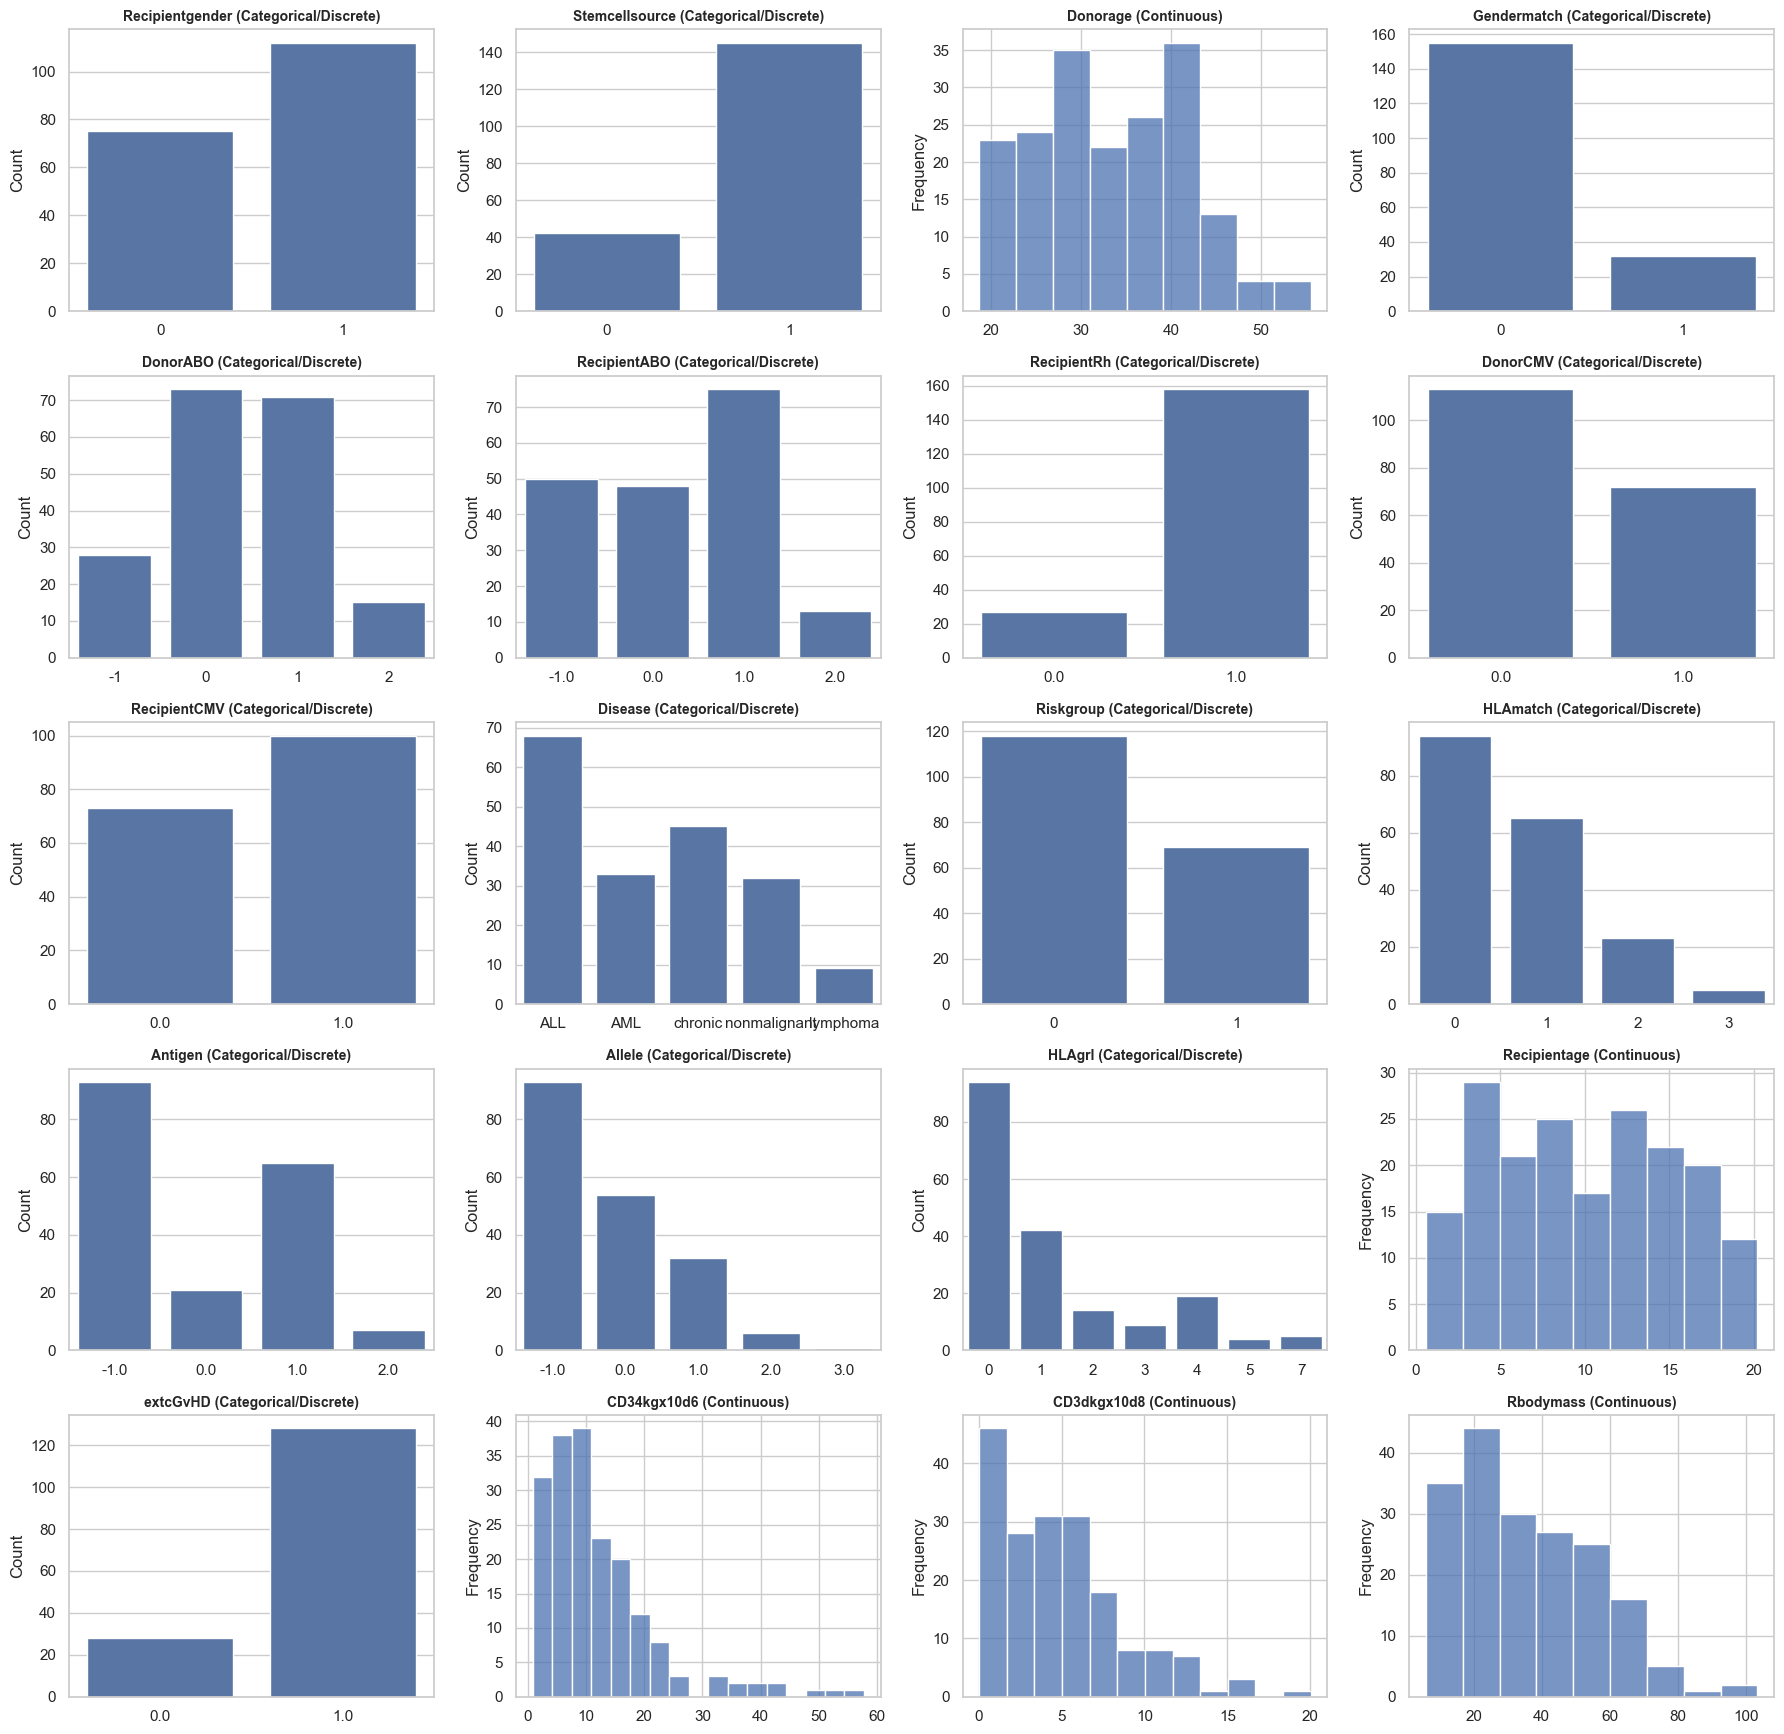

In [13]:
sns.set_theme(style="whitegrid")

# Define grid size dynamically
num_vars = len(X.columns)
ncols = 4
nrows = math.ceil(num_vars / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 3.5))
axes = axes.flatten()

# Plot each variable based on cardinality
for i, col in enumerate(X.columns):
    ax = axes[i]
    if X[col].nunique() <= 10:
        sns.countplot(data=X, x=col, ax=ax)
        ax.set_title(f"{col} (Categorical/Discrete)", fontsize=10, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("Count")
    else:
        sns.histplot(data=X, x=col,  ax=ax)
        ax.set_title(f"{col} (Continuous)", fontsize=10, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("Frequency")

# Hide extra empty subplots in the grid
for j in range(num_vars, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Missing Values

Some of our variables have missing values which will be addressed now

extcGvHD        16.577540
RecipientCMV     7.486631
CD3dkgx10d8      2.673797
DonorCMV         1.069519
RecipientRh      1.069519
Rbodymass        1.069519
Antigen          0.534759
RecipientABO     0.534759
Allele           0.534759
dtype: float64


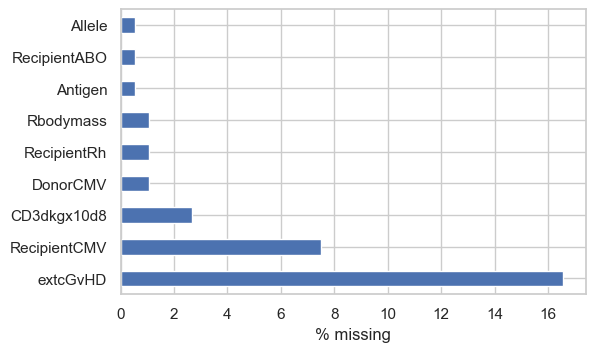

In [14]:
missing_pct = (X.isna().mean() * 100).sort_values(ascending=False)
miss = missing_pct[missing_pct > 0]
print(miss)

miss.plot.barh(figsize=(6, 0.3 * len(miss) + 1))
plt.xlabel("% missing"); plt.show()

As we have binary, continuous and categorical variables.

For variables which have less than 3% of missing values, we will use mode imputation, just in case, to avoid 0.5 values. For Continuous Variables, we will use median imputation.

For remaining variables, we will use an Iterative Imputer with Random Forests.

In [15]:
# Encoding strings for RF
X_encoded = pd.get_dummies(X, columns=["Disease"], drop_first=True)

# Variables with < 3% missingness
mode_cols = ["RecipientRh", "DonorCMV", "Antigen", "RecipientABO", "Allele"]
median_cols = ["Rbodymass", "CD3dkgx10d8"]

# Variables with >3% missingness
rf_binary_cols = ["RecipientCMV", "extcGvHD"]

X_imputed = X_encoded.copy()

if mode_cols:
    mode_imp = SimpleImputer(strategy="most_frequent")
    X_imputed[mode_cols] = mode_imp.fit_transform(X_imputed[mode_cols])

if median_cols:
    median_imp = SimpleImputer(strategy="median")
    X_imputed[median_cols] = median_imp.fit_transform(X_imputed[median_cols])

rf_imputer = IterativeImputer(
    estimator=ExtraTreesRegressor(n_estimators=100, random_state=42),
    max_iter=10,
    random_state=42,
)

X_final = pd.DataFrame(
    rf_imputer.fit_transform(X_imputed), columns=X_imputed.columns
)

# Rounding just in case for binary columns
for col in rf_binary_cols:
    X_final[col] = X_final[col].round().astype(int)


c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [16]:
print(X_final.isna().sum().sum())
X_final

0


,Recipientgender,Stemcellsource,Donorage,Gendermatch,DonorABO,RecipientABO,RecipientRh,DonorCMV,RecipientCMV,Riskgroup,HLAmatch,Antigen,Allele,HLAgrI,Recipientage,extcGvHD,CD34kgx10d6,CD3dkgx10d8,Rbodymass,Disease_AML,Disease_chronic,Disease_lymphoma,Disease_nonmalignant
0,1.0,1.0,22.830137,0.0,1.0,1.0,1.0,1.0,1,1.0,0.0,-1.0,-1.0,0.0,9.6,1,7.20,5.38,35.0,0.0,0.0,0.0,0.0
1,1.0,0.0,23.342466,0.0,-1.0,-1.0,1.0,0.0,0,0.0,0.0,-1.0,-1.0,0.0,4.0,1,4.50,0.41,20.6,0.0,0.0,0.0,0.0
2,1.0,0.0,26.394521,0.0,-1.0,-1.0,1.0,0.0,1,0.0,0.0,-1.0,-1.0,0.0,6.6,1,7.94,0.42,23.4,0.0,0.0,0.0,0.0
3,0.0,0.0,39.684932,0.0,1.0,2.0,1.0,1.0,0,0.0,0.0,-1.0,-1.0,0.0,18.1,0,4.25,0.14,50.0,1.0,0.0,0.0,0.0
4,0.0,1.0,33.358904,0.0,1.0,2.0,0.0,0.0,1,1.0,1.0,1.0,0.0,1.0,1.3,1,51.85,13.05,9.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182,1.0,1.0,37.575342,0.0,1.0,1.0,0.0,1.0,1,1.0,0.0,-1.0,-1.0,0.0,12.9,1,11.08,4.39,44.0,0.0,0.0,1.0,0.0
183,0.0,1.0,22.895890,0.0,1.0,0.0,1.0,0.0,1,1.0,0.0,-1.0,-1.0,0.0,13.9,1,4.64,4.47,44.5,1.0,0.0,0.0,0.0
184,0.0,1.0,27.347945,0.0,1.0,-1.0,1.0,1.0,1,0.0,0.0,-1.0,-1.0,0.0,10.4,1,7.73,4.73,33.0,0.0,0.0,0.0,1.0
185,1.0,1.0,27.780822,0.0,1.0,0.0,1.0,0.0,0,0.0,1.0,1.0,0.0,1.0,8.0,0,15.41,1.91,24.0,0.0,1.0,0.0,0.0


In [17]:
# Undoing the disease one-hot encoding
disease_cols = [c for c in X_final.columns if c.startswith("Disease_")]

X_final["Disease"] = X_final[disease_cols].idxmax(axis=1).str.replace(
    "Disease_", ""
)

X_final.loc[X_final[disease_cols].sum(axis=1) == 0, "Disease"] = "ALL"

X_final = X_final.drop(columns=disease_cols)

Missing values have been correctly removed

## Target Correlation

Obtaining a correlation matrix between the features and the targets to evaluate impact of certain features on the target column.

We will use both Pearson and Spearman, as Pearson assumes data normality as well as a linear relationship. On the other hand, Spearman does not make any data assumption, it is robust to outliers and it measures if both variables tend to move in the same direction (not necessarily linear)

In [18]:
# Correlation to the two target variables
X_corr = X_final.copy()
X_corr["Disease"] = X_corr["Disease"].astype("category").cat.codes
target = y["survival_time"] 

pearson_corr = X_corr.corrwith(target, method="pearson")
spearman_corr = X_corr.corrwith(target, method="spearman")

# Compute correlation against survival_status (binary event)
pearson_status = X_corr.corrwith(y["survival_status"], method="pearson")
spearman_status = X_corr.corrwith(y["survival_status"], method="spearman")

# Combined overview table for both targets
all_corrs_abs = (
    pd.DataFrame(
        {
            "time_spearman": spearman_corr.abs(),
            "time_pearson": pearson_corr.abs(),
            "status_spearman": spearman_status.abs(),
            "status_pearson": pearson_status.abs(),
        }
    )
)

print(all_corrs_abs.head())


                 time_spearman  time_pearson  status_spearman  status_pearson
Recipientgender       0.047499      0.060487         0.023905        0.023905
Stemcellsource        0.045815      0.041253         0.126335        0.126335
Donorage              0.013431      0.005603         0.046753        0.060384
Gendermatch           0.072467      0.110597         0.012962        0.012962
DonorABO              0.001856      0.016415         0.004025        0.015193


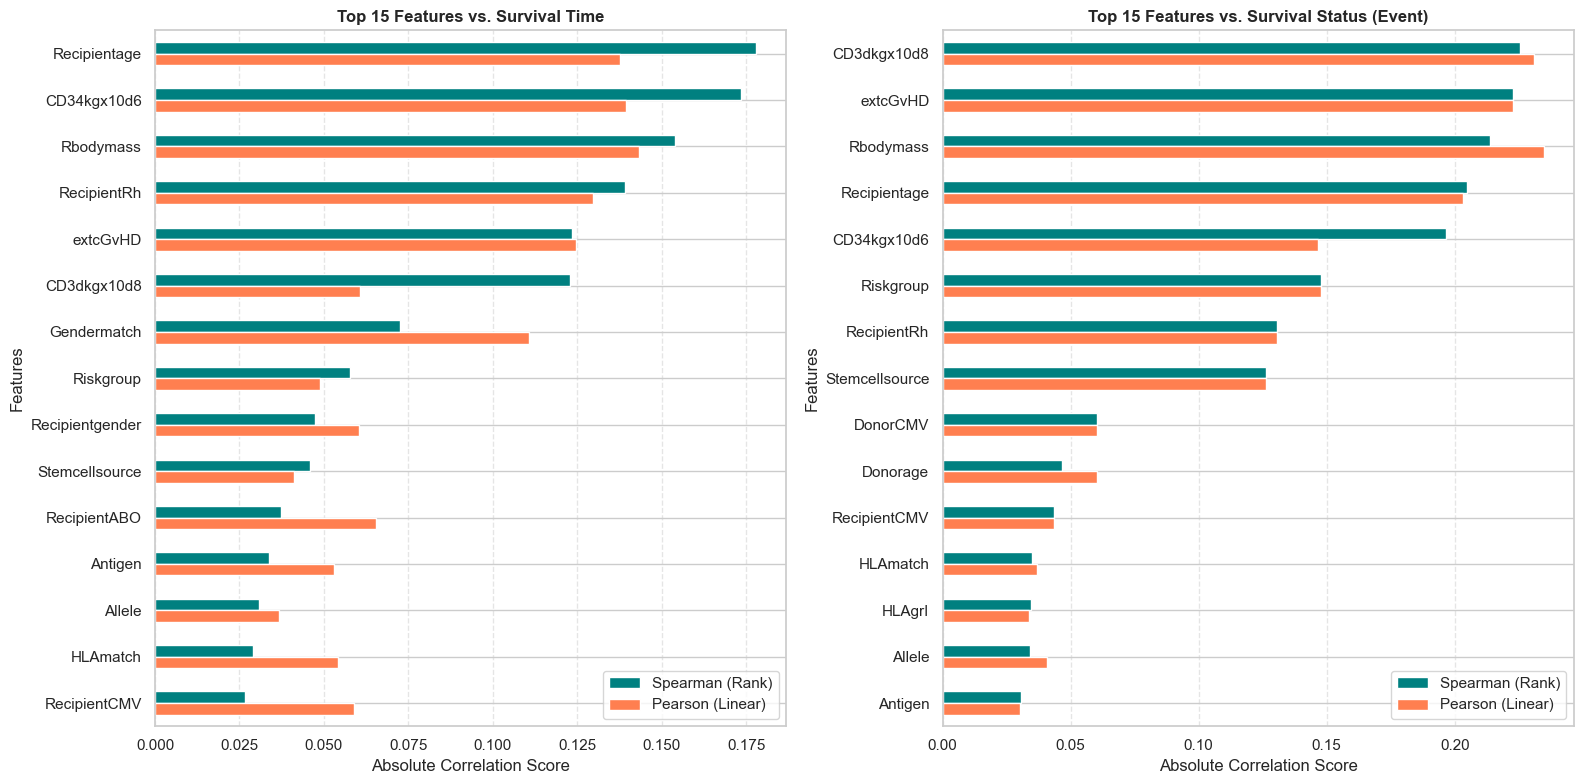

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Top 15 survival time
top_time = all_corrs_abs.sort_values(
    by="time_spearman", ascending=False
).head(15)
top_time[["time_spearman", "time_pearson"]].plot(
    kind="barh", ax=axes[0], color=["teal", "coral"]
)
axes[0].invert_yaxis()
axes[0].set_title(
    "Top 15 Features vs. Survival Time", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Absolute Correlation Score")
axes[0].set_ylabel("Features")
axes[0].legend(["Spearman (Rank)", "Pearson (Linear)"])
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

top_status = all_corrs_abs.sort_values(
    by="status_spearman", ascending=False
).head(15)
top_status[["status_spearman", "status_pearson"]].plot(
    kind="barh", ax=axes[1], color=["teal", "coral"]
)
axes[1].invert_yaxis()
axes[1].set_title(
    "Top 15 Features vs. Survival Status (Event)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Absolute Correlation Score")
axes[1].set_ylabel("Features")
axes[1].legend(["Spearman (Rank)", "Pearson (Linear)"])
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Relevant Features

Combining different correlation values we will select the most important variables.

This methods allow us to detect non-linear relationships, it also evaluates the impact of both target variables and it provides robustness as it takes into account different correlation methods

In [20]:
feature_metrics = pd.DataFrame(
    {
        "time_spearman": spearman_corr.abs(),
        "time_pearson": pearson_corr.abs(),
        "status_spearman": spearman_status.abs(),
        "status_pearson": pearson_status.abs(),
    }
).fillna(0)

# Normalize each column to a [0, 1] scale for equal weighting
norm_df = feature_metrics.apply(
    lambda x: (x - x.min()) / (x.max() - x.min() + 1e-9)
)

# Calculating a mixed score with equal weights to all values
feature_metrics["composite_score"] = (
    0.25*norm_df["time_pearson"]
    + 0.25 * norm_df["time_spearman"]
    + 0.25 * norm_df["status_spearman"]
    + 0.25 * norm_df["status_pearson"]

)

# Rank features by composite score
feature_summary = feature_metrics.sort_values(
    by="composite_score", ascending=False
).round(4)

print(feature_summary)

                 time_spearman  time_pearson  ...  status_pearson  composite_score
Rbodymass               0.1538        0.1434  ...          0.2349           0.9523
Recipientage            0.1780        0.1376  ...          0.2034           0.9310
extcGvHD                0.1233        0.1248  ...          0.2228           0.8732
CD34kgx10d6             0.1733        0.1393  ...          0.1467           0.8545
CD3dkgx10d8             0.1228        0.0607  ...          0.2308           0.7725
RecipientRh             0.1391        0.1298  ...          0.1306           0.6967
Riskgroup               0.0578        0.0488  ...          0.1477           0.4784
Stemcellsource          0.0458        0.0413  ...          0.1263           0.4001
Gendermatch             0.0725        0.1106  ...          0.0130           0.3039
RecipientCMV            0.0268        0.0589  ...          0.0436           0.2178
Recipientgender         0.0475        0.0605  ...          0.0239           0.2055
HLAm

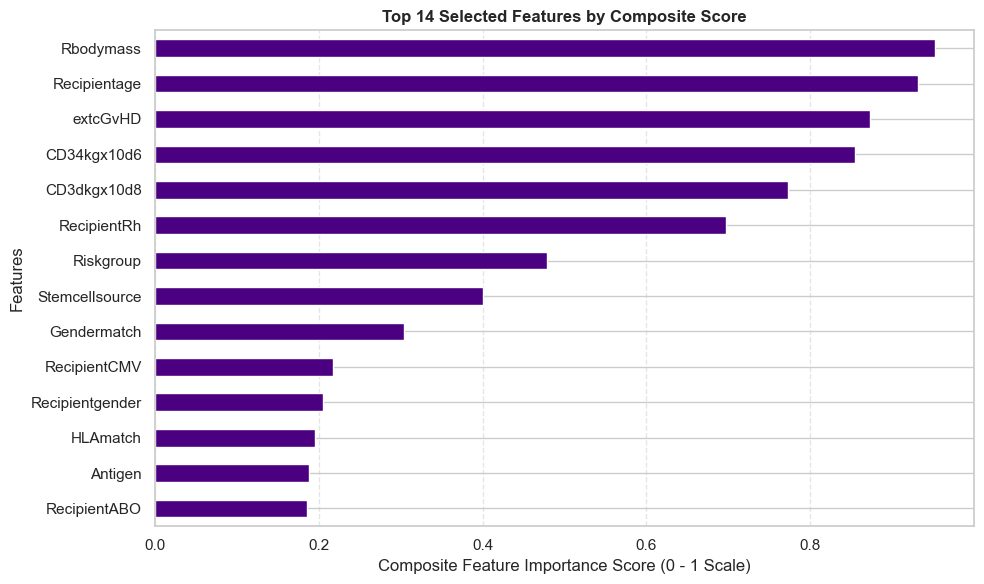

In [21]:
plt.figure(figsize=(10, 6))
feature_summary["composite_score"].head(14).plot(
    kind="barh", color="indigo"
).invert_yaxis()
plt.title(
    "Top 14 Selected Features by Composite Score", fontsize=12, fontweight="bold"
)
plt.xlabel("Composite Feature Importance Score (0 - 1 Scale)")
plt.ylabel("Features")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [22]:
# We cutoff features below a 0.1 composite score. We see there is a 0.96 gap between variables here and this means that it does not rank high among all methods.
# This is 17 total features

selected_features = feature_summary.head(17).index.tolist()
X_selected = X_final[selected_features]
X_selected

,Rbodymass,Recipientage,extcGvHD,CD34kgx10d6,CD3dkgx10d8,RecipientRh,Riskgroup,Stemcellsource,Gendermatch,RecipientCMV,Recipientgender,HLAmatch,Antigen,RecipientABO,Allele,HLAgrI,DonorCMV
0,35.0,9.6,1,7.20,5.38,1.0,1.0,1.0,0.0,1,1.0,0.0,-1.0,1.0,-1.0,0.0,1.0
1,20.6,4.0,1,4.50,0.41,1.0,0.0,0.0,0.0,0,1.0,0.0,-1.0,-1.0,-1.0,0.0,0.0
2,23.4,6.6,1,7.94,0.42,1.0,0.0,0.0,0.0,1,1.0,0.0,-1.0,-1.0,-1.0,0.0,0.0
3,50.0,18.1,0,4.25,0.14,1.0,0.0,0.0,0.0,0,0.0,0.0,-1.0,2.0,-1.0,0.0,1.0
4,9.0,1.3,1,51.85,13.05,0.0,1.0,1.0,0.0,1,0.0,1.0,1.0,2.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182,44.0,12.9,1,11.08,4.39,0.0,1.0,1.0,0.0,1,1.0,0.0,-1.0,1.0,-1.0,0.0,1.0
183,44.5,13.9,1,4.64,4.47,1.0,1.0,1.0,0.0,1,0.0,0.0,-1.0,0.0,-1.0,0.0,0.0
184,33.0,10.4,1,7.73,4.73,1.0,0.0,1.0,0.0,1,0.0,0.0,-1.0,-1.0,-1.0,0.0,1.0
185,24.0,8.0,0,15.41,1.91,1.0,0.0,1.0,0.0,0,1.0,1.0,1.0,0.0,0.0,1.0,0.0


We have reduced our total dataframe from 36 columns to a total of 17, through redundancy, handling missing values, dealing with after-transplant variables and correlation

In [32]:
y

,survival_time,survival_status
0,999,0
1,163,1
2,435,1
3,53,1
4,2043,0
...,...,...
182,385,1
183,634,1
184,1895,0
185,382,1


## PCA

We will use PCA to view our current data and we will also obtain its scores to obtain the relevant variables.

In [50]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Sacling before PCA is applied
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_selected)

# PCAs
pca = PCA(n_components=5) # We use 5 components to gain more insights about possible unimportant variables
x_pca = pca.fit_transform(X_scaled)


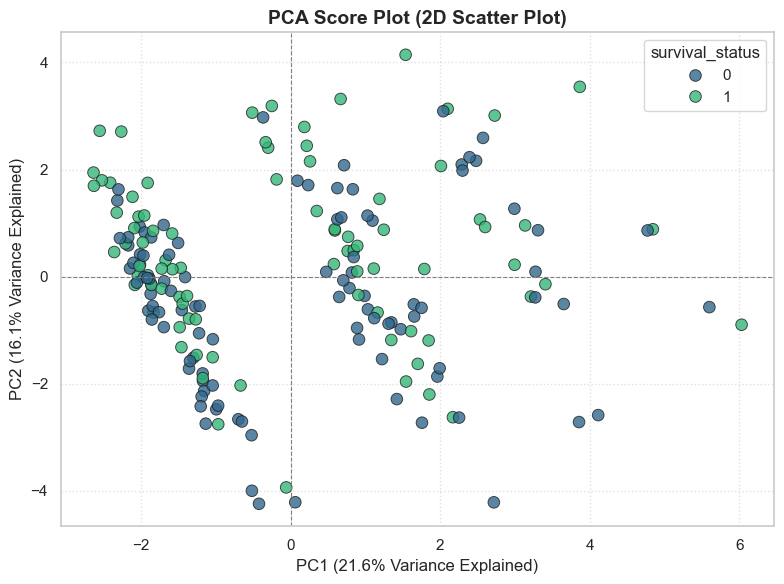

In [51]:
# Calculate percentage of explained variance for each component
var_exp = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(8, 6))

# Plot PC1 vs PC2 
sns.scatterplot(
    x=x_pca[:, 0],
    y=x_pca[:, 1],
    hue=y["survival_status"] if 'y' in locals() else None,
    palette='viridis',
    s=70,
    alpha=0.8,
    edgecolor='k'
)

plt.title('PCA Score Plot (2D Scatter Plot)', fontsize=14, fontweight='bold')
plt.xlabel(f'PC1 ({var_exp[0]:.1f}% Variance Explained)', fontsize=12)
plt.ylabel(f'PC2 ({var_exp[1]:.1f}% Variance Explained)', fontsize=12)

# Reference axes
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)

plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Both components explain a similar amount of variance of the model, around 20%.

We will obtain the explained variance from the principal components

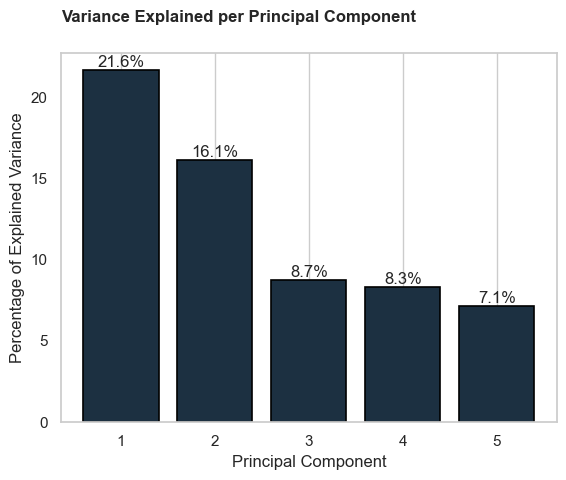

In [52]:
plot_y = [val * 100 for val in pca.explained_variance_ratio_]
plot_x = range(1, len(plot_y) + 1)

bars = plt.bar(plot_x, plot_y, align="center", color="#1C3041", edgecolor="#000000", linewidth=1.2)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.001, f"{yval:.1f}%", ha="center", va="bottom")

plt.xlabel("Principal Component")
plt.ylabel("Percentage of Explained Variance")
plt.title("Variance Explained per Principal Component", loc="left", fontdict={"weight": "bold"}, y=1.06)
plt.grid(axis="y")
plt.xticks(plot_x)

plt.show()

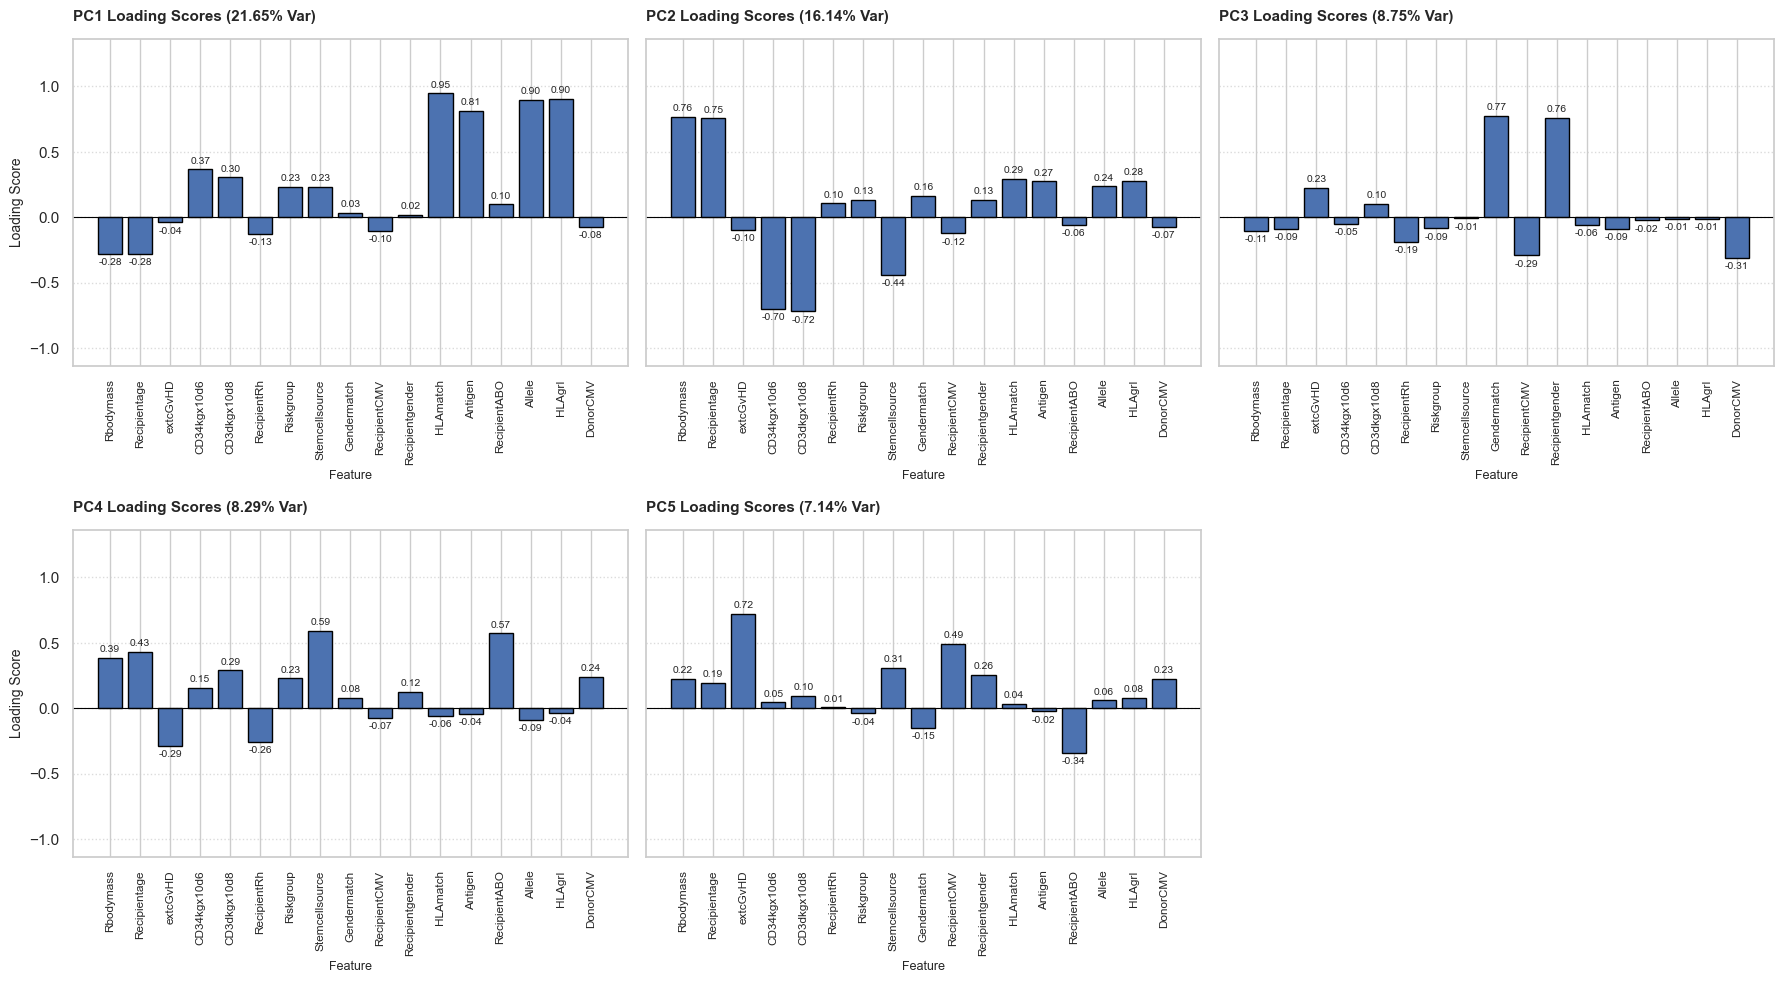

In [53]:
# Computing the loadings, scaled by square root of eigenvalues
loadings = pd.DataFrame(
    data=pca.components_.T * np.sqrt(pca.explained_variance_),
    columns=[f"PC{i}" for i in range(1, pca.n_components_ + 1)],
    index=X_selected.columns
)

n_pcs = pca.n_components_
ncols = 3
nrows = (n_pcs + ncols - 1) // ncols

fig, axs = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows), sharey=True)
axs = axs.flatten()

y_min, y_max = loadings.values.min(), loadings.values.max()
y_margin = (y_max - y_min) * 0.25

for i in range(n_pcs):
    ax = axs[i]
    pc = f"PC{i+1}"
    explained_variance = pca.explained_variance_ratio_[i] * 100
    
    bars = ax.bar(
        loadings.index, 
        loadings[pc], 
        edgecolor="#000000", 
        linewidth=1.0
    )
    
    ax.set_title(
        f"{pc} Loading Scores ({explained_variance:.2f}% Var)",
        loc="left",
        fontdict={"weight": "bold", "size": 11},
        y=1.03
    )
    ax.set_xlabel("Feature", fontsize=9)
    if i % ncols == 0:
        ax.set_ylabel("Loading Score", fontsize=10)
        
    ax.grid(axis="y", linestyle=":", alpha=0.7)
    ax.tick_params(axis="x", rotation=90, labelsize=8.5)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylim(min(-1.1, y_min - y_margin), max(1.1, y_max + y_margin))

    # Add numeric value text on each bar
    for bar in bars:
        yval = bar.get_height()
        va = "bottom" if yval >= 0 else "top"
        offset = 0.03 if yval >= 0 else -0.03
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            yval + offset,
            f"{yval:.2f}",
            ha="center",
            va=va,
            fontsize=7.5
        )

# Unused graph
for j in range(n_pcs, len(axs)):
    fig.delaxes(axs[j])

plt.tight_layout()
plt.show()


First component is largely influenced by Allele, RecipientGender, HLAgrl, suggesting this component focuses on the match and alignment between donor and host.

The second component gives more weight to   RBodymass, RecipientAge will haveing an inverse relationship to CD34 and CD3 cells, variables which are tightly connected as cell dose is given in concentrations per kilogram.

We will remove variables which have a small loading score across all the components.

In [59]:
# Calculate max absolute loading for each feature across the 5 PCs
max_loadings = loadings.abs().max(axis=1)
max_loadings.sort_values(ascending=False)

HLAmatch           0.945651
HLAgrI             0.901925
Allele             0.895060
Antigen            0.810547
Gendermatch        0.772457
Rbodymass          0.764514
Recipientgender    0.760221
Recipientage       0.754643
CD3dkgx10d8        0.719518
extcGvHD           0.719101
CD34kgx10d6        0.701826
Stemcellsource     0.589878
RecipientABO       0.571585
RecipientCMV       0.490227
DonorCMV           0.309417
RecipientRh        0.257237
Riskgroup          0.230546
dtype: float64

There is a big gap between Recipient CMV and Donor CMV, however, as the first component focused on the match between donor and recipient, we will set a threshold of 0.3 and remove the rest of variables.

In [61]:
threshold = 0.30
features_to_keep = max_loadings[max_loadings >= threshold].index
features_to_remove = max_loadings[max_loadings < threshold].index

print("Features to keep :", list(features_to_keep))
print("Features to remove :", list(features_to_remove))


X_reduced = X_selected[features_to_keep]

Features to keep : ['Rbodymass', 'Recipientage', 'extcGvHD', 'CD34kgx10d6', 'CD3dkgx10d8', 'Stemcellsource', 'Gendermatch', 'RecipientCMV', 'Recipientgender', 'HLAmatch', 'Antigen', 'RecipientABO', 'Allele', 'HLAgrI', 'DonorCMV']
Features to remove : ['RecipientRh', 'Riskgroup']


In [62]:
X_reduced

,Rbodymass,Recipientage,extcGvHD,CD34kgx10d6,CD3dkgx10d8,Stemcellsource,Gendermatch,RecipientCMV,Recipientgender,HLAmatch,Antigen,RecipientABO,Allele,HLAgrI,DonorCMV
0,35.0,9.6,1,7.20,5.38,1.0,0.0,1,1.0,0.0,-1.0,1.0,-1.0,0.0,1.0
1,20.6,4.0,1,4.50,0.41,0.0,0.0,0,1.0,0.0,-1.0,-1.0,-1.0,0.0,0.0
2,23.4,6.6,1,7.94,0.42,0.0,0.0,1,1.0,0.0,-1.0,-1.0,-1.0,0.0,0.0
3,50.0,18.1,0,4.25,0.14,0.0,0.0,0,0.0,0.0,-1.0,2.0,-1.0,0.0,1.0
4,9.0,1.3,1,51.85,13.05,1.0,0.0,1,0.0,1.0,1.0,2.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182,44.0,12.9,1,11.08,4.39,1.0,0.0,1,1.0,0.0,-1.0,1.0,-1.0,0.0,1.0
183,44.5,13.9,1,4.64,4.47,1.0,0.0,1,0.0,0.0,-1.0,0.0,-1.0,0.0,0.0
184,33.0,10.4,1,7.73,4.73,1.0,0.0,1,0.0,0.0,-1.0,-1.0,-1.0,0.0,1.0
185,24.0,8.0,0,15.41,1.91,1.0,0.0,0,1.0,1.0,1.0,0.0,0.0,1.0,0.0


# Saving dataset

We will save our current preprocessed dataset to csv, so we can open it in a different notebook without having to run all the cells

In [63]:
X_reduced.to_csv("bone_marrow.csv")